In [1]:
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parents[1]))

from deep_models.lib_models import load_folds, S00MILDataset
from torch.utils.data import DataLoader
import torch

To get some intuition on the latent space dimension need, let's perform PCA on the instances and see how CEV looks like. 

In [ ]:
developmental_folds_read_out = load_folds("splits/s00_developmental.npz")

== Fold 0 ==
  80% variance: 53 components
  90% variance: 136 components
  95% variance: 286 components
  99% variance: 671 components
  Participation ratio: 31.95

== Fold 1 ==
  80% variance: 54 components
  90% variance: 140 components
  95% variance: 292 components
  99% variance: 676 components
  Participation ratio: 32.64

== Fold 2 ==
  80% variance: 53 components
  90% variance: 135 components
  95% variance: 281 components
  99% variance: 663 components
  Participation ratio: 32.93

== Fold 3 ==
  80% variance: 54 components
  90% variance: 137 components
  95% variance: 286 components
  99% variance: 667 components
  Participation ratio: 33.30

== Fold 4 ==
  80% variance: 54 components
  90% variance: 139 components
  95% variance: 287 components
  99% variance: 670 components
  Participation ratio: 32.86

== Fold 5 ==
  80% variance: 53 components
  90% variance: 133 components
  95% variance: 280 components
  99% variance: 665 components
  Participation ratio: 31.99

== F

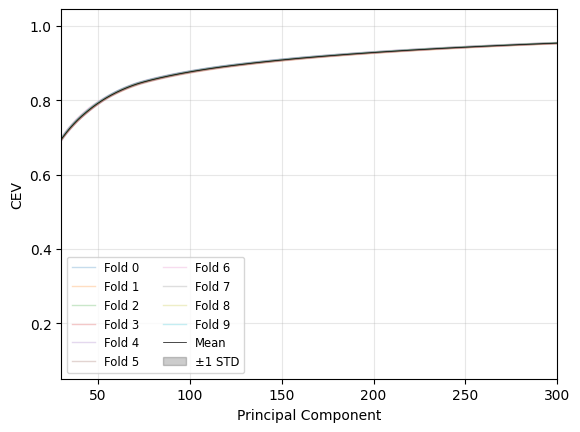

In [9]:
THRESHOLDS = (0.80, 0.90, 0.95, 0.99)

cums, prs = [], []

for fold, fold_data in enumerate(developmental_folds_read_out[:10]):
    dataset = S00MILDataset(fold_data, max_instances=150, train=True)
    loader = DataLoader(dataset, batch_size=10, num_workers=2)

    batches = [
        (b[0] if isinstance(b, (list, tuple)) else b).detach().cpu().flatten(0, 1)
        for b in loader
    ]
    X = torch.cat(batches).flatten(1).numpy()

    pca = PCA().fit(X)
    ev = pca.explained_variance_
    cum = np.cumsum(pca.explained_variance_ratio_)
    pr = ev.sum() ** 2 / (ev ** 2).sum()

    cums.append(cum)
    prs.append(pr)

    print(f"== Fold {fold} ==")
    for thr in THRESHOLDS:
        print(f"  {thr:.0%} variance: {np.searchsorted(cum, thr) + 1} components")
    print(f"  Participation ratio: {pr:.2f}\n")

print(f"Mean PR: {np.mean(prs):.2f} ± {np.std(prs):.2f}")

# Align lengths in case any fold has fewer samples than features
min_len = min(len(c) for c in cums)
cums_arr = np.array([c[:min_len] for c in cums])
mean_cum, std_cum = cums_arr.mean(axis=0), cums_arr.std(axis=0)
pcs = np.arange(1, min_len + 1)  # 1-indexed for log x-axis

fig, ax = plt.subplots()

for fold, cum in enumerate(cums_arr):
    ax.plot(pcs, cum, alpha=0.25, lw=1, label=f"Fold {fold}")

ax.plot(pcs, mean_cum, color="black", lw=0.5, label="Mean")
ax.fill_between(pcs, mean_cum - std_cum, mean_cum + std_cum, color="black", alpha=0.2, label="±1 STD")

ax.set(xlabel="Principal Component", ylabel="CEV")
ax.grid(True, which="both", alpha=0.3)
ax.legend(ncol=2, fontsize="small")
plt.xlim(30, 300)
plt.show()